Spectrum of Cesium-137

In [13]:
import matplotlib.pyplot as plt
import numpy as np
from lmfit import models

In [14]:
h_Cs = 243.17576721634862 
h_Na_1 = 197.22530992597498
h_Na_2 = 499.298182758717

E_Cs = 661.638 #keV
E_Na_1 = 511.006 #keV
E_Na_2 = 1274.511

E_err_Cs = 0.019 #keV
E_err_Na_1 = 0 #keV
E_err_Na_2 = 0.028 #keV

h_Cs_err = 0.1595702654960676
h_Na_err_1 = 0.4509864330864726
h_Na_err_2 = 3.7916435080428266


E = [E_Cs, E_Na_1, E_Na_2]
E_err = [E_err_Cs, E_err_Na_1, E_err_Na_2]
E_inv_err = [1/E_err_Cs, 9999999999999, 1/E_err_Na_2]
h_err = [h_Cs_err, h_Na_err_1, h_Na_err_2]
h = [h_Cs, h_Na_1, h_Na_2]

In [15]:
h_err_array = np.array(h_err)

h_inv_err = 1 / h_err_array
h_inv_err = list(h_inv_err)

In [16]:
def linear_model(x,a,b):
    y = a*x + b
    return y

In [17]:
spectrum = models.Model(linear_model)
fit_result = spectrum.fit(E, x=h, a=1, b=26, weights=E_inv_err)

print(fit_result.fit_report())

[[Model]]
    Model(linear_model)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 10
    # data points      = 3
    # variables        = 2
    chi-square         = 3137476.34
    reduced chi-square = 3137476.34
    Akaike info crit   = 45.5809511
    Bayesian info crit = 43.7781757
    R-squared          = 0.99634297
[[Variables]]
    a:  2.56347073 +/- 0.16020913 (6.25%) (init = 1)
    b:  5.42469115 +/- 31.5972945 (582.47%) (init = 26)
[[Correlations]] (unreported correlations are < 0.100)
    C(a, b) = -1.0000


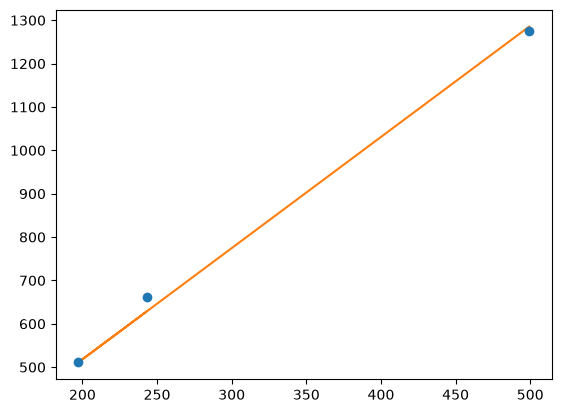

In [18]:
plt.errorbar(h,E,yerr=h_err, fmt='o')
plt.plot(h, fit_result.best_fit)
# plt.ylim(0,1000)
# plt.xlim(0, 2000)
plt.show()